<a href="https://colab.research.google.com/github/Musa62/my-soc-ops-python/blob/main/321_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install CoolProp

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 61.7 MB/s eta 0:00:00


In [2]:
import CoolProp.CoolProp as CP

# Operating Boundary Conditions
P_high = 10.0e6         # 10.0 MPa (100 bar)
T_high = 540.0 + 273.15 # 813.15 K
P_rh = 2.0e6            # 2.0 MPa (20 bar)
T_rh = 540.0 + 273.15   # 813.15 K
P_cond = 8.0e3          # 8.0 kPa (0.08 bar)

# Component Efficiencies
eta_t = 0.88            # Turbine isentropic efficiency
eta_p = 0.85            # Pump isentropic efficiency
W_net_target = 100.0e6 / 0.96  # 104.167 MW net shaft power

# State 1: HP Turbine Inlet
h1 = CP.PropsSI('H', 'P', P_high, 'T', T_high, 'Water')
s1 = CP.PropsSI('S', 'P', P_high, 'T', T_high, 'Water')

# State 2: HP Turbine Exhaust & Extraction Bleed
s2s = s1
h2s = CP.PropsSI('H', 'P', P_rh, 'S', s2s, 'Water')
h2a = h1 - eta_t * (h1 - h2s)
s2a = CP.PropsSI('S', 'P', P_rh, 'H', h2a, 'Water')

# State 4: LP Turbine Inlet (Post-Reheat)
h4 = CP.PropsSI('H', 'P', P_rh, 'T', T_rh, 'Water')
s4 = CP.PropsSI('S', 'P', P_rh, 'T', T_rh, 'Water')

# State 5: LP Turbine Exhaust
s5s = s4
h5s = CP.PropsSI('H', 'P', P_cond, 'S', s5s, 'Water')
h5a = h4 - eta_t * (h4 - h5s)
x5a = CP.PropsSI('Q', 'P', P_cond, 'H', h5a, 'Water')

# Pumping and Deaeration States (6 to 9)
h6 = CP.PropsSI('H', 'P', P_cond, 'Q', 0.0, 'Water')
v6 = 1.0 / CP.PropsSI('D', 'P', P_cond, 'Q', 0.0, 'Water')
wp1 = (v6 * (P_rh - P_cond)) / eta_p
h7 = h6 + wp1

h8 = CP.PropsSI('H', 'P', P_rh, 'Q', 0.0, 'Water')
v8 = 1.0 / CP.PropsSI('D', 'P', P_rh, 'Q', 0.0, 'Water')
wp2 = (v8 * (P_high - P_rh)) / eta_p
h9 = h8 + wp2

# Extraction Fraction Balance
y = (h8 - h7) / (h2a - h7)

# Cycle Energetics
wt = (h1 - h2a) + (1.0 - y) * (h4 - h5a)
wp = (1.0 - y) * wp1 + wp2
wnet = wt - wp

qin = (h1 - h9) + (1.0 - y) * (h4 - h2a)
qout = (1.0 - y) * (h5a - h6)

eta_th = wnet / qin
m_dot = W_net_target / wnet
ssc = 3600.0 / (wnet / 1e3)

print(f"Extraction Fraction y: {y:.4f}")
print(f"Thermal Efficiency: {eta_th*100:.2f}%")
print(f"Steam Mass Flow: {m_dot:.2f} kg/s ({m_dot*3.6:.1f} t/h)")
print(f"Exhaust Vapor Quality: {x5a:.4f}")

Extraction Fraction y: 0.2541
Thermal Efficiency: 40.64%
Steam Mass Flow: 87.51 kg/s (315.0 t/h)
Exhaust Vapor Quality: 0.9704


In [3]:
import CoolProp.CoolProp as CP

# =========================================================
# 1. STANDARDIZED OPERATING BOUNDARY CONDITIONS (CASE 5)
# =========================================================
P_high = 10.0e6          # 10.0 MPa (100 bar)
T_high = 540.0 + 273.15  # 813.15 K
P_rh   = 2.0e6           # 2.0 MPa (20 bar)
T_rh   = 540.0 + 273.15  # 813.15 K
P_cond = 8.0e3           # 8.0 kPa (0.08 bar)

eta_t = 0.88             # Turbine Isentropic Efficiency (88%)
eta_p = 0.85             # Pump Isentropic Efficiency (85%)
eta_g = 0.96             # Generator Efficiency (96%)

W_electric = 100.0e6     # 100.0 MWe net electrical power
W_shaft = W_electric / eta_g  # Required shaft power (104.167 MW)

# =========================================================
# 2. THERMODYNAMIC STATE CALCULATIONS (IAPWS-IF97)
# =========================================================
# State 1: HP Turbine Inlet
h1 = CP.PropsSI('H', 'P', P_high, 'T', T_high, 'Water') / 1e3  # kJ/kg
s1 = CP.PropsSI('S', 'P', P_high, 'T', T_high, 'Water') / 1e3  # kJ/(kg·K)

# State 2: HP Turbine Exhaust & Extraction Split
s2s = s1
h2s = CP.PropsSI('H', 'P', P_rh, 'S', s2s * 1e3, 'Water') / 1e3
h2a = h1 - eta_t * (h1 - h2s)

# State 4: LP Turbine Inlet (Post-Reheat)
h4 = CP.PropsSI('H', 'P', P_rh, 'T', T_rh, 'Water') / 1e3
s4 = CP.PropsSI('S', 'P', P_rh, 'T', T_rh, 'Water') / 1e3

# State 5: LP Turbine Exhaust
s5s = s4
h5s = CP.PropsSI('H', 'P', P_cond, 'S', s5s * 1e3, 'Water') / 1e3
h5a = h4 - eta_t * (h4 - h5s)
x5a = CP.PropsSI('Q', 'P', P_cond, 'H', h5a * 1e3, 'Water')  # Dryness fraction

# States 6 to 9: Condensate, Pumps, and Deaerator
h6  = CP.PropsSI('H', 'P', P_cond, 'Q', 0.0, 'Water') / 1e3
v6  = 1.0 / CP.PropsSI('D', 'P', P_cond, 'Q', 0.0, 'Water')
wp1 = (v6 * (P_rh - P_cond)) / (eta_p * 1e3)  # Condensate pump work (kJ/kg)
h7  = h6 + wp1

h8  = CP.PropsSI('H', 'P', P_rh, 'Q', 0.0, 'Water') / 1e3
v8  = 1.0 / CP.PropsSI('D', 'P', P_rh, 'Q', 0.0, 'Water')
wp2 = (v8 * (P_high - P_rh)) / (eta_p * 1e3)  # Boiler feed pump work (kJ/kg)
h9  = h8 + wp2

# =========================================================
# 3. ENERGETICS & PARAMETER DETERMINATION
# =========================================================
# Stage Specific Works
w_hp = h1 - h2a                         # HP Turbine Work (kJ/kg)
w_lp = h4 - h5a                         # LP Turbine Work (kJ/kg)

# Extraction Fraction (y)
y = (h8 - h7) / (h2a - h7)              # Bleed Ratio

# Net Works & Heat Duties
w_t_total = w_hp + (1.0 - y) * w_lp     # Total turbine work per kg main steam
w_p_total = (1.0 - y) * wp1 + wp2       # Total pump work per kg main steam
w_net     = w_t_total - w_p_total       # Net specific work (kJ/kg)

q_in   = (h1 - h9) + (1.0 - y) * (h4 - h2a)  # Total heat supplied (kJ/kg)
eta_th = (w_net / q_in) * 100.0               # Thermal Efficiency (%)

m_dot = (W_shaft / 1e3) / w_net               # Steam Mass Flow Rate (kg/s)

# =========================================================
# 4. PRINT COMPARATIVE TABLE
# =========================================================
# Reference Analytical Values from Report Table 7.2
analytical_ref = {
    "HP Turbine Work (kJ/kg)": 421.87,
    "LP Turbine Work (kJ/kg)": 1039.69,
    "Bleed Ratio (y)":          0.2546,
    "Net Work, w_net (kJ/kg)": 1184.02,
    "Thermal Efficiency (%)":   40.41,
    "Steam Mass Flow (kg/s)":   87.98,
    "Exhaust Quality (x)":      0.9748
}

python_calc = {
    "HP Turbine Work (kJ/kg)": w_hp,
    "LP Turbine Work (kJ/kg)": w_lp,
    "Bleed Ratio (y)":          y,
    "Net Work, w_net (kJ/kg)": w_net,
    "Thermal Efficiency (%)":   eta_th,
    "Steam Mass Flow (kg/s)":   m_dot,
    "Exhaust Quality (x)":      x5a
}

print("\n" + "=" * 70)
print(f"{'Parameter':<26} | {'Analytical':<12} | {'Python':<12} | {'Dev (%)':<8}")
print("=" * 70)

for param in analytical_ref:
    ref_val  = analytical_ref[param]
    calc_val = python_calc[param]
    dev      = abs((calc_val - ref_val) / ref_val) * 100.0

    if "Ratio" in param or "Quality" in param:
        print(f"{param:<26} | {ref_val:<12.4f} | {calc_val:<12.4f} | {dev:<8.2f}%")
    else:
        print(f"{param:<26} | {ref_val:<12.2f} | {calc_val:<12.2f} | {dev:<8.2f}%")

print("=" * 70)


Parameter                  | Analytical   | Python       | Dev (%) 
HP Turbine Work (kJ/kg)    | 421.87       | 418.69       | 0.75    %
LP Turbine Work (kJ/kg)    | 1039.69      | 1051.72      | 1.16    %
Bleed Ratio (y)            | 0.2546       | 0.2541       | 0.20    %
Net Work, w_net (kJ/kg)    | 1184.02      | 1190.34      | 0.53    %
Thermal Efficiency (%)     | 40.41        | 40.64        | 0.56    %
Steam Mass Flow (kg/s)     | 87.98        | 87.51        | 0.53    %
Exhaust Quality (x)        | 0.9748       | 0.9704       | 0.45    %


In [4]:
!pip install CoolProp matplotlib numpy

<>:78: SyntaxWarning: invalid escape sequence '\e'
<>:86: SyntaxWarning: invalid escape sequence '\e'
<>:78: SyntaxWarning: invalid escape sequence '\e'
<>:86: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_2414/1302048296.py:78: SyntaxWarning: invalid escape sequence '\e'
  ax.plot([s1, s2a], [T1, T2a], '#dc2626', lw=2.2, label='HP Turbine Expansion ($\eta_t = 88\%$)')
/tmp/ipykernel_2414/1302048296.py:86: SyntaxWarning: invalid escape sequence '\e'
  ax.plot([s4, s5a], [T4, T5a], '#7c3aed', lw=2.2, label='LP Turbine Expansion ($\eta_t = 88\%$)')


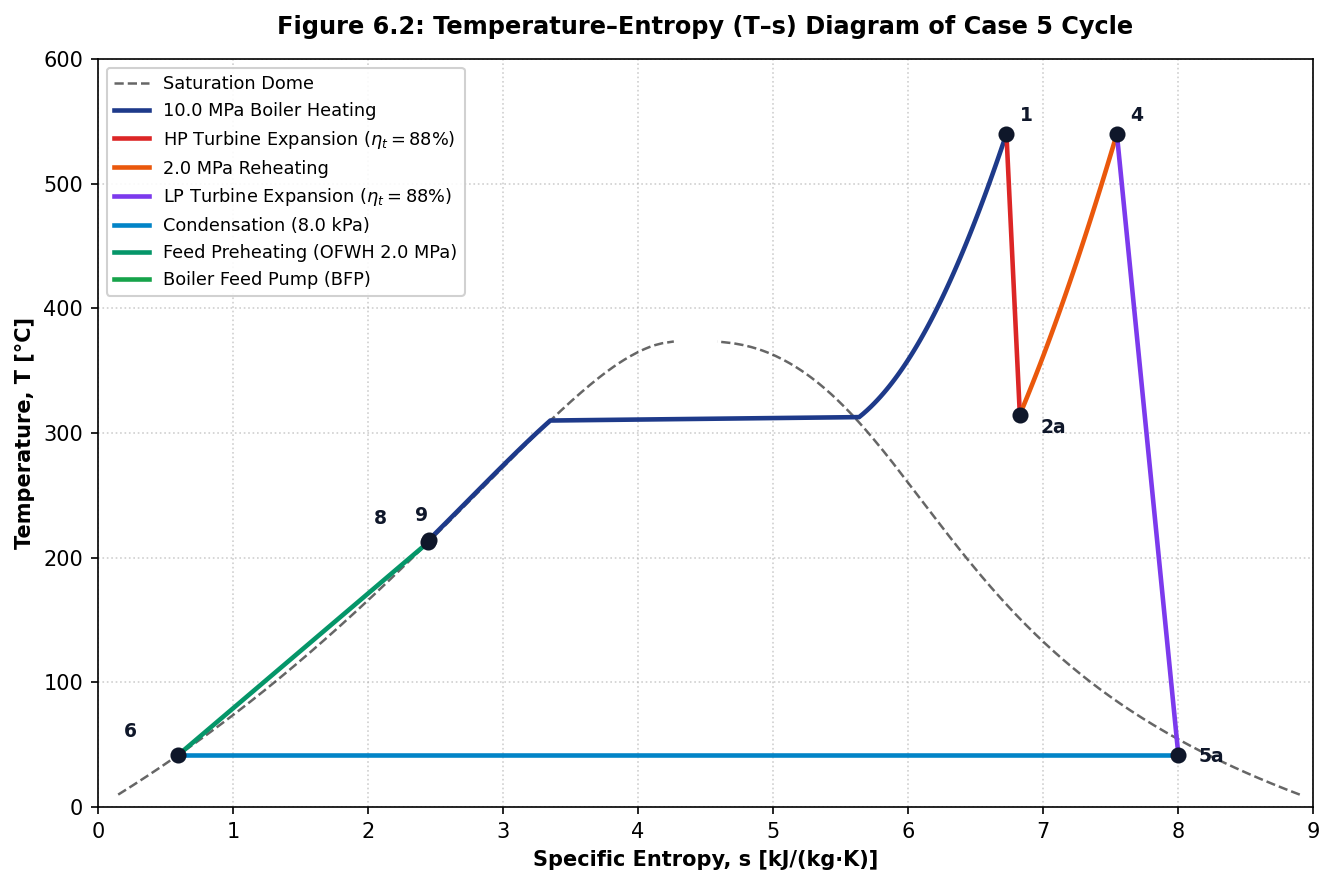

In [5]:
import CoolProp.CoolProp as CP
import matplotlib.pyplot as plt
import numpy as np

# Set up figure styling
fig, ax = plt.subplots(figsize=(9, 6), dpi=150)

# =========================================================
# 1. GENERATE THE SATURATION DOME (s_f and s_g)
# =========================================================
T_crit = CP.PropsSI('Tcrit', 'Water') - 273.15
T_range = np.linspace(273.15 + 10, CP.PropsSI('Tcrit', 'Water') - 0.5, 250)

sf_dome = [CP.PropsSI('S', 'T', t, 'Q', 0, 'Water') / 1e3 for t in T_range]
sg_dome = [CP.PropsSI('S', 'T', t, 'Q', 1, 'Water') / 1e3 for t in T_range]
T_dome_C = T_range - 273.15

ax.plot(sf_dome, T_dome_C, 'k--', linewidth=1.2, label='Saturation Dome', alpha=0.6)
ax.plot(sg_dome, T_dome_C, 'k--', linewidth=1.2, alpha=0.6)

# =========================================================
# 2. COMPUTE CASE 5 STATE POINTS
# =========================================================
P_high, T_high = 10.0e6, 540.0 + 273.15
P_rh, T_rh = 2.0e6, 540.0 + 273.15
P_cond = 8.0e3
eta_t, eta_p = 0.88, 0.85

# State 1: Main Steam
h1 = CP.PropsSI('H', 'P', P_high, 'T', T_high, 'Water') / 1e3
s1 = CP.PropsSI('S', 'P', P_high, 'T', T_high, 'Water') / 1e3
T1 = 540.0

# State 2a: HP Turbine Exit
s2s = s1
h2s = CP.PropsSI('H', 'P', P_rh, 'S', s2s * 1e3, 'Water') / 1e3
h2a = h1 - eta_t * (h1 - h2s)
s2a = CP.PropsSI('S', 'P', P_rh, 'H', h2a * 1e3, 'Water') / 1e3
T2a = CP.PropsSI('T', 'P', P_rh, 'H', h2a * 1e3, 'Water') - 273.15

# State 4: LP Turbine Inlet (Post-Reheat)
h4 = CP.PropsSI('H', 'P', P_rh, 'T', T_rh, 'Water') / 1e3
s4 = CP.PropsSI('S', 'P', P_rh, 'T', T_rh, 'Water') / 1e3
T4 = 540.0

# State 5a: LP Turbine Exhaust
s5s = s4
h5s = CP.PropsSI('H', 'P', P_cond, 'S', s5s * 1e3, 'Water') / 1e3
h5a = h4 - eta_t * (h4 - h5s)
s5a = CP.PropsSI('S', 'P', P_cond, 'H', h5a * 1e3, 'Water') / 1e3
T5a = CP.PropsSI('T', 'P', P_cond, 'H', h5a * 1e3, 'Water') - 273.15

# State 6: Condenser Outlet
s6 = CP.PropsSI('S', 'P', P_cond, 'Q', 0.0, 'Water') / 1e3
T6 = CP.PropsSI('T', 'P', P_cond, 'Q', 0.0, 'Water') - 273.15

# State 8: Deaerator Outlet (Sat. Liquid at 2.0 MPa)
s8 = CP.PropsSI('S', 'P', P_rh, 'Q', 0.0, 'Water') / 1e3
T8 = CP.PropsSI('T', 'P', P_rh, 'Q', 0.0, 'Water') - 273.15

# State 9: Boiler Feed Pump Outlet
v8 = 1.0 / CP.PropsSI('D', 'P', P_rh, 'Q', 0.0, 'Water')
wp2 = (v8 * (P_high - P_rh)) / (eta_p * 1e3)
h8 = CP.PropsSI('H', 'P', P_rh, 'Q', 0.0, 'Water') / 1e3
h9 = h8 + wp2
s9 = CP.PropsSI('S', 'P', P_high, 'H', h9 * 1e3, 'Water') / 1e3
T9 = CP.PropsSI('T', 'P', P_high, 'H', h9 * 1e3, 'Water') - 273.15

# =========================================================
# 3. PLOT PROCESS LINES & PATHS
# =========================================================
# 9 -> 1: Boiler Heating, Evaporation & Superheating
T_boil = np.linspace(T9 + 273.15, T_high, 120)
s_boil = [CP.PropsSI('S', 'P', P_high, 'T', t, 'Water') / 1e3 for t in T_boil]
ax.plot(s_boil, T_boil - 273.15, '#1e3a8a', lw=2.2, label='10.0 MPa Boiler Heating')

# 1 -> 2a: HP Turbine Expansion
ax.plot([s1, s2a], [T1, T2a], '#dc2626', lw=2.2, label='HP Turbine Expansion ($\eta_t = 88\%$)')

# 2a -> 4: Reheater
T_reheat = np.linspace(T2a + 273.15, T_rh, 60)
s_reheat = [CP.PropsSI('S', 'P', P_rh, 'T', t, 'Water') / 1e3 for t in T_reheat]
ax.plot(s_reheat, T_reheat - 273.15, '#ea580c', lw=2.2, label='2.0 MPa Reheating')

# 4 -> 5a: LP Turbine Expansion
ax.plot([s4, s5a], [T4, T5a], '#7c3aed', lw=2.2, label='LP Turbine Expansion ($\eta_t = 88\%$)')

# 5a -> 6: Condensation
ax.plot([s5a, s6], [T5a, T6], '#0284c7', lw=2.2, label='Condensation (8.0 kPa)')

# 6 -> 8: Feedwater Preheating in OFWH
ax.plot([s6, s8], [T6, T8], '#059669', lw=2.2, label='Feed Preheating (OFWH 2.0 MPa)')

# 8 -> 9: BFP Compression
ax.plot([s8, s9], [T8, T9], '#16a34a', lw=2.2, label='Boiler Feed Pump (BFP)')

# =========================================================
# 4. ANNOTATE STATE POINTS & FORMAT GRAPH
# =========================================================
state_pts = {
    '1': (s1, T1, (0.1, 10)),
    '2a': (s2a, T2a, (0.15, -15)),
    '4': (s4, T4, (0.1, 10)),
    '5a': (s5a, T5a, (0.15, -5)),
    '6': (s6, T6, (-0.4, 15)),
    '8': (s8, T8, (-0.4, 15)),
    '9': (s9, T9, (-0.1, 15))
}

for label, (x, y, offset) in state_pts.items():
    ax.scatter(x, y, color='#0f172a', s=45, zorder=5)
    ax.annotate(f"{label}", (x, y), xytext=(x + offset[0], y + offset[1]),
                fontweight='bold', fontsize=9, color='#0f172a')

ax.set_title('Figure 6.2: Temperature–Entropy (T–s) Diagram of Case 5 Cycle', fontsize=11.5, fontweight='bold', pad=12)
ax.set_xlabel('Specific Entropy, s [kJ/(kg·K)]', fontsize=10, fontweight='bold')
ax.set_ylabel('Temperature, T [°C]', fontsize=10, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.6)
ax.set_xlim(0, 9.0)
ax.set_ylim(0, 600)
ax.legend(loc='upper left', fontsize=8.5, frameon=True, framealpha=0.9)

# Render plot in Colab output
plt.tight_layout()
plt.show()

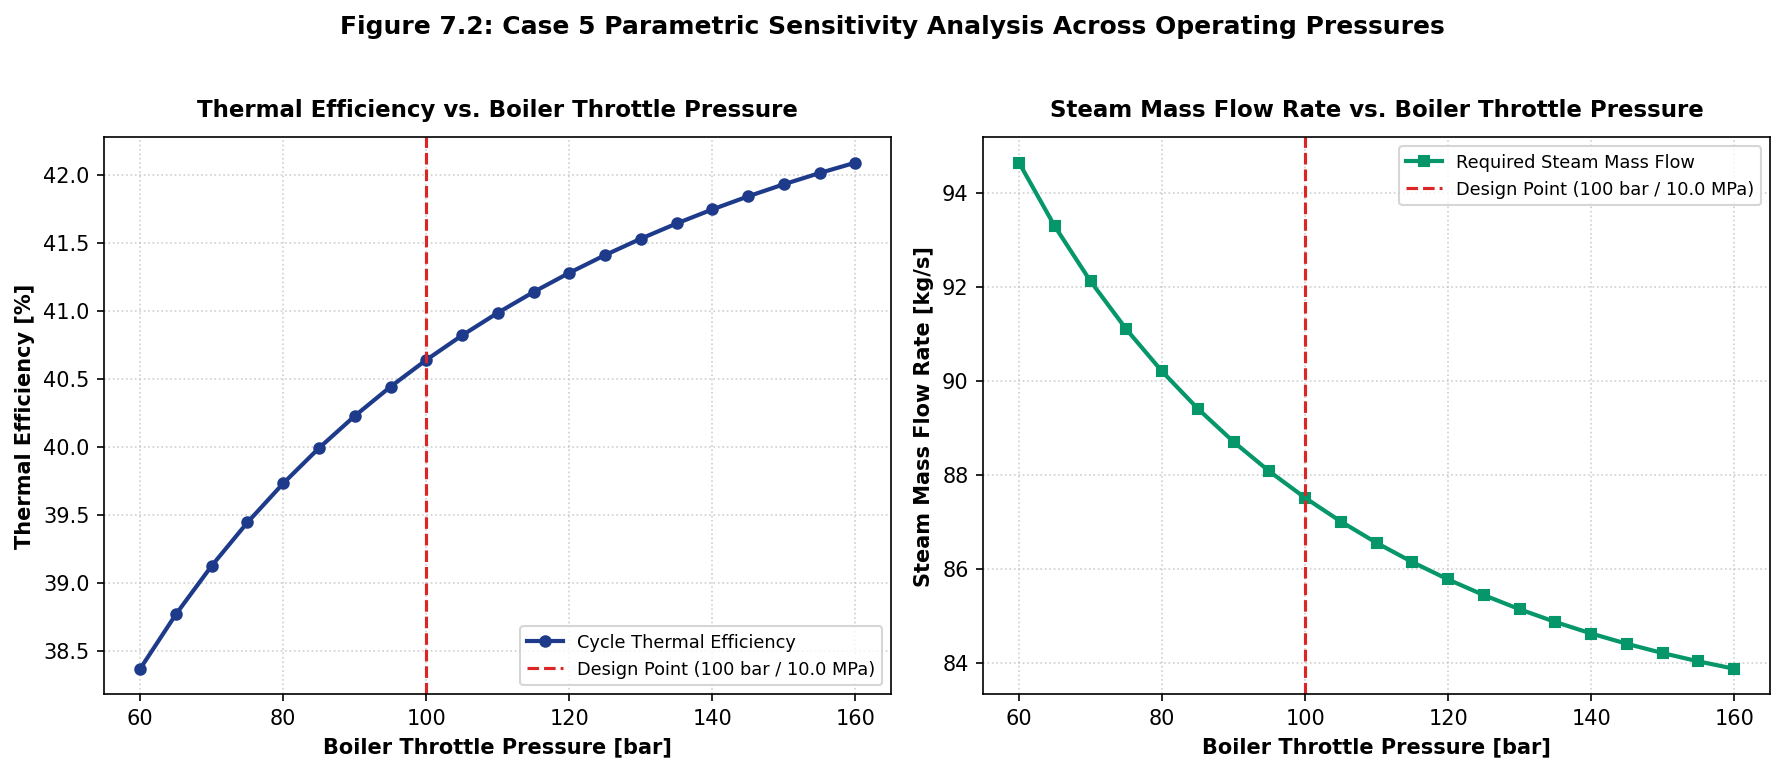

In [6]:
import CoolProp.CoolProp as CP
import matplotlib.pyplot as plt
import numpy as np

# =========================================================
# 1. FIXED OPERATING BOUNDARY CONDITIONS & EFFICIENCIES
# =========================================================
T_high = 540.0 + 273.15  # Main steam temp (813.15 K)
P_rh   = 2.0e6           # Reheat pressure (2.0 MPa / 20 bar)
T_rh   = 540.0 + 273.15  # Reheat temp (813.15 K)
P_cond = 8.0e3           # Condenser backpressure (8.0 kPa)

eta_t = 0.88             # Turbine isentropic efficiency
eta_p = 0.85             # Pump isentropic efficiency
eta_g = 0.96             # Generator efficiency

W_electric = 100.0e6     # 100.0 MWe net electrical output
W_shaft = W_electric / eta_g  # Required shaft power (104.167 MW)

# =========================================================
# 2. PARAMETRIC SWEEP FUNCTION ACROSS BOILER PRESSURE
# =========================================================
def calculate_case5(P_high_val):
    # State 1: HP Turbine Inlet
    h1 = CP.PropsSI('H', 'P', P_high_val, 'T', T_high, 'Water') / 1e3
    s1 = CP.PropsSI('S', 'P', P_high_val, 'T', T_high, 'Water') / 1e3

    # State 2: HP Turbine Exhaust
    s2s = s1
    h2s = CP.PropsSI('H', 'P', P_rh, 'S', s2s * 1e3, 'Water') / 1e3
    h2a = h1 - eta_t * (h1 - h2s)

    # State 4: LP Turbine Inlet
    h4 = CP.PropsSI('H', 'P', P_rh, 'T', T_rh, 'Water') / 1e3
    s4 = CP.PropsSI('S', 'P', P_rh, 'T', T_rh, 'Water') / 1e3

    # State 5: LP Turbine Exhaust
    s5s = s4
    h5s = CP.PropsSI('H', 'P', P_cond, 'S', s5s * 1e3, 'Water') / 1e3
    h5a = h4 - eta_t * (h4 - h5s)
    x5a = CP.PropsSI('Q', 'P', P_cond, 'H', h5a * 1e3, 'Water')

    # States 6-9: Pumping and Deaeration
    h6  = CP.PropsSI('H', 'P', P_cond, 'Q', 0.0, 'Water') / 1e3
    v6  = 1.0 / CP.PropsSI('D', 'P', P_cond, 'Q', 0.0, 'Water')
    wp1 = (v6 * (P_rh - P_cond)) / (eta_p * 1e3)
    h7  = h6 + wp1

    h8  = CP.PropsSI('H', 'P', P_rh, 'Q', 0.0, 'Water') / 1e3
    v8  = 1.0 / CP.PropsSI('D', 'P', P_rh, 'Q', 0.0, 'Water')
    wp2 = (v8 * (P_high_val - P_rh)) / (eta_p * 1e3)
    h9  = h8 + wp2

    # Energetics & Performance
    y = (h8 - h7) / (h2a - h7)
    wt = (h1 - h2a) + (1.0 - y) * (h4 - h5a)
    wp = (1.0 - y) * wp1 + wp2
    wnet = wt - wp

    qin = (h1 - h9) + (1.0 - y) * (h4 - h2a)
    eta_th = (wnet / qin) * 100.0
    m_dot = (W_shaft / 1e3) / wnet

    return eta_th, m_dot, x5a, wnet

# =========================================================
# 3. SWEEP OVER BOILER PRESSURES (60 bar to 160 bar)
# =========================================================
p_bar_range = np.linspace(60, 160, 21)  # Pressure range in bar
p_pa_range  = p_bar_range * 1e5          # Pressure range in Pa

eff_list, mdot_list, x_list, wnet_list = [], [], [], []

for p in p_pa_range:
    eta_th, m_dot, x5a, wnet = calculate_case5(p)
    eff_list.append(eta_th)
    mdot_list.append(m_dot)
    x_list.append(x5a)
    wnet_list.append(wnet)

# =========================================================
# 4. PLOT PARAMETRIC SENSITIVITY DIAGRAMS
# =========================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=150)

# Plot 1: Thermal Efficiency vs Boiler Pressure
ax1.plot(p_bar_range, eff_list, marker='o', color='#1e3a8a', linewidth=2, markersize=5, label='Cycle Thermal Efficiency')
ax1.axvline(100, color='#dc2626', linestyle='--', linewidth=1.5, label='Design Point (100 bar / 10.0 MPa)')
ax1.set_title('Thermal Efficiency vs. Boiler Throttle Pressure', fontsize=11, fontweight='bold', pad=10)
ax1.set_xlabel('Boiler Throttle Pressure [bar]', fontsize=10, fontweight='bold')
ax1.set_ylabel('Thermal Efficiency [%]', fontsize=10, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='lower right', fontsize=8.5)

# Plot 2: Steam Flow Rate vs Boiler Pressure
ax2.plot(p_bar_range, mdot_list, marker='s', color='#059669', linewidth=2, markersize=5, label='Required Steam Mass Flow')
ax2.axvline(100, color='#dc2626', linestyle='--', linewidth=1.5, label='Design Point (100 bar / 10.0 MPa)')
ax2.set_title('Steam Mass Flow Rate vs. Boiler Throttle Pressure', fontsize=11, fontweight='bold', pad=10)
ax2.set_xlabel('Boiler Throttle Pressure [bar]', fontsize=10, fontweight='bold')
ax2.set_ylabel('Steam Mass Flow Rate [kg/s]', fontsize=10, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', fontsize=8.5)

plt.suptitle('Figure 7.2: Case 5 Parametric Sensitivity Analysis Across Operating Pressures', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()